In [5]:
import re
import os
import time
import warnings

import torch
import torchvision.transforms.functional as F
import matplotlib.pyplot as plt

from torch.export import export
from torchvision.io import decode_image

from executorch import version
from executorch.runtime import Runtime
from executorch.exir import to_edge_transform_and_lower
from executorch.backends.apple.coreml.partition import CoreMLPartitioner

from transformer_net import TransformerNet


warnings.simplefilter("ignore", FutureWarning)
print("Executorch version: ", version.__version__)

Executorch version:  1.1.0


In [2]:
# NOTE: Use `download_saved_models.py` to download the pre-trained models before
# running this export script.
STYLES_MODELS = {
    "candy": "saved_models/candy.pth",
    "mosaic": "saved_models/mosaic.pth",
    "udnie": "saved_models/udnie.pth",
    "rain_princess": "saved_models/rain_princess.pth",
}

# NOTE: Per
# http://docs.pytorch.org/executorch/1.1/backends/coreml/coreml-troubleshooting.html
# 'Note that the model will be still be converted to FP16 during lowering to
# Core ML unless specified otherwise in the compute_precision'
SUFFIX = "_coreml_fp16"
EXPORT_DIR = "exports"
MODEL_PATH: dict[str, str] = {}

# NOTE: The original code does not resize the input image, since the network is
# fully convolutional and can handle arbitrary input sizes. However, for the
# exported model, we need to resize the input to a fixed size. The particular
# size of 640x640 is chosen to be large enough to preserve details while being
# small enough for efficient inference. This size was also used in the original
# export.
RESIZE_SIZE = [640, 640]


# Based on the implementation of `stylize()` function from:
# https://github.com/pytorch/examples/blob/main/fast_neural_style/neural_style/neural_style.py
def load_style_transfer_model(wts_path: str) -> torch.nn.Module:
    state_dict = torch.load(wts_path)
    for k in list(state_dict.keys()):
        if re.search(r"in\d+\.running_(mean|var)$", k):
            del state_dict[k]

    model = TransformerNet()
    model.load_state_dict(state_dict)
    model.eval()
    return model

In [3]:
print("Exporting models...")

for model_name, wts_path in STYLES_MODELS.items():
    model = load_style_transfer_model(wts_path)
    inputs = (torch.randn(1, 3, *RESIZE_SIZE),)

    program = to_edge_transform_and_lower(export(model, inputs), partitioner=[CoreMLPartitioner()])
    program = program.to_executorch()

    with open(path := f"{EXPORT_DIR}/style_transfer_{model_name}{SUFFIX}.pte", "wb") as f:
        MODEL_PATH[model_name] = path
        f.write(program.buffer)

    print(f"Exported {path}\n")

Exporting models...


Running MIL backend_mlprogram pipeline: 100%|██████████| 12/12 [00:00<00:00, 251.12 passes/s]


Exported exports/style_transfer_candy_coreml_fp16.pte



INFO:executorch.backends.apple.coreml.partition.coreml_partitioner:CoreMLPartitioner::partition
INFO:executorch.backends.apple.coreml.partition.coreml_partitioner:Skipping op for CoreML delegation because it is not get_attr or call_function: output
INFO:executorch.backends.apple.coreml.partition.coreml_partitioner:Skipping op for CoreML delegation because it is not get_attr or call_function: placeholder
INFO:executorch.backends.apple.coreml.partition.coreml_partitioner:Core ML partitioner will take over torch mutable buffer as Core ML state, so if your model contains mutable buffer, then you will need MacOS15+/iOS18+ to execute. If you want your mutable buffer model to be compatible with older OS, then please set `take_over_mutable_buffer=False`
Running MIL backend_mlprogram pipeline: 100%|██████████| 12/12 [00:00<00:00, 232.76 passes/s]


Exported exports/style_transfer_mosaic_coreml_fp16.pte



INFO:executorch.backends.apple.coreml.partition.coreml_partitioner:CoreMLPartitioner::partition
INFO:executorch.backends.apple.coreml.partition.coreml_partitioner:Skipping op for CoreML delegation because it is not get_attr or call_function: output
INFO:executorch.backends.apple.coreml.partition.coreml_partitioner:Skipping op for CoreML delegation because it is not get_attr or call_function: placeholder
INFO:executorch.backends.apple.coreml.partition.coreml_partitioner:Core ML partitioner will take over torch mutable buffer as Core ML state, so if your model contains mutable buffer, then you will need MacOS15+/iOS18+ to execute. If you want your mutable buffer model to be compatible with older OS, then please set `take_over_mutable_buffer=False`
Running MIL backend_mlprogram pipeline: 100%|██████████| 12/12 [00:00<00:00, 243.74 passes/s]


Exported exports/style_transfer_udnie_coreml_fp16.pte



INFO:executorch.backends.apple.coreml.partition.coreml_partitioner:CoreMLPartitioner::partition
INFO:executorch.backends.apple.coreml.partition.coreml_partitioner:Skipping op for CoreML delegation because it is not get_attr or call_function: output
INFO:executorch.backends.apple.coreml.partition.coreml_partitioner:Skipping op for CoreML delegation because it is not get_attr or call_function: placeholder
INFO:executorch.backends.apple.coreml.partition.coreml_partitioner:Core ML partitioner will take over torch mutable buffer as Core ML state, so if your model contains mutable buffer, then you will need MacOS15+/iOS18+ to execute. If you want your mutable buffer model to be compatible with older OS, then please set `take_over_mutable_buffer=False`
Running MIL backend_mlprogram pipeline: 100%|██████████| 12/12 [00:00<00:00, 242.06 passes/s]


Exported exports/style_transfer_rain_princess_coreml_fp16.pte



[program.cpp:154] InternalConsistency verification requested but not available
[ETCoreMLModelManager.mm:478] Cache Miss: Compiled Model with identifier=executorch_dd5e5372-f60a-43fe-8356-44b3c357e99a_all was not found in the models cache.
[ETCoreMLModelManager.mm:457] The model in the pte file is not pre-compiled.  Compiling with a 5 min timeout.
[ETCoreMLModelManager.mm:490] Successfully got compiled model with identifier=executorch_dd5e5372-f60a-43fe-8356-44b3c357e99a_all.  Transferring ownership to assetManager.


Verifying models...
CANDY
Model size: 3.62 MB
Run successfully via Executorch in 3.33 seconds



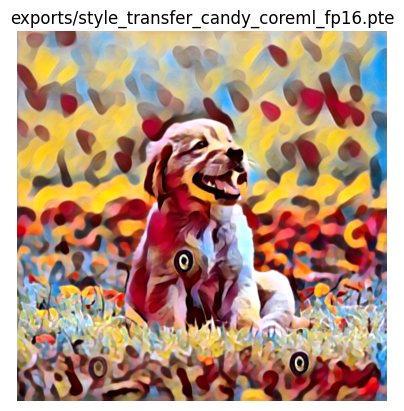

[program.cpp:154] InternalConsistency verification requested but not available
[ETCoreMLModelManager.mm:478] Cache Miss: Compiled Model with identifier=executorch_f6325d76-0fc9-42ea-a07d-23d4a93c5fd1_all was not found in the models cache.
[ETCoreMLModelManager.mm:457] The model in the pte file is not pre-compiled.  Compiling with a 5 min timeout.
[ETCoreMLModelManager.mm:490] Successfully got compiled model with identifier=executorch_f6325d76-0fc9-42ea-a07d-23d4a93c5fd1_all.  Transferring ownership to assetManager.


MOSAIC
Model size: 3.62 MB
Run successfully via Executorch in 3.45 seconds



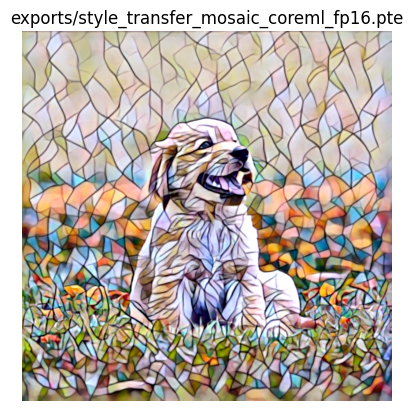

[program.cpp:154] InternalConsistency verification requested but not available
[ETCoreMLModelManager.mm:478] Cache Miss: Compiled Model with identifier=executorch_5a6b8748-e1b9-4bad-909b-9f3b4915c76e_all was not found in the models cache.
[ETCoreMLModelManager.mm:457] The model in the pte file is not pre-compiled.  Compiling with a 5 min timeout.
[ETCoreMLModelManager.mm:490] Successfully got compiled model with identifier=executorch_5a6b8748-e1b9-4bad-909b-9f3b4915c76e_all.  Transferring ownership to assetManager.


UDNIE
Model size: 3.62 MB
Run successfully via Executorch in 3.47 seconds



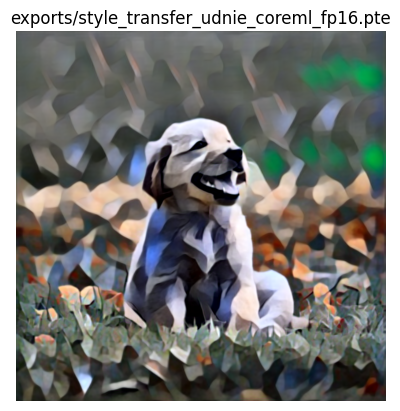

[program.cpp:154] InternalConsistency verification requested but not available
[ETCoreMLModelManager.mm:478] Cache Miss: Compiled Model with identifier=executorch_4211ef07-2b02-4095-a4af-59ad63c00fc8_all was not found in the models cache.
[ETCoreMLModelManager.mm:457] The model in the pte file is not pre-compiled.  Compiling with a 5 min timeout.
[ETCoreMLModelManager.mm:490] Successfully got compiled model with identifier=executorch_4211ef07-2b02-4095-a4af-59ad63c00fc8_all.  Transferring ownership to assetManager.


RAIN_PRINCESS
Model size: 3.62 MB
Run successfully via Executorch in 3.17 seconds



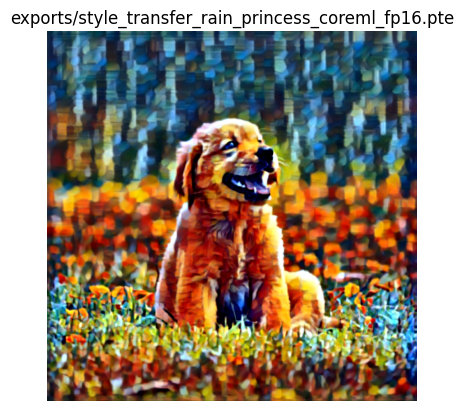

In [4]:
print("Verifying models...")

for model_name, wts_path in STYLES_MODELS.items():
    print(model_name.upper())
    path = MODEL_PATH[model_name]

    # --- Executorch inference ---
    img = decode_image("assets/dog.png").unsqueeze(0)
    img = F.resize(img, RESIZE_SIZE)
    img = F.convert_image_dtype(img, torch.float)

    t = time.perf_counter()
    runtime = Runtime.get()
    program = runtime.load_program(path)
    output, *_ = program.load_method("forward").execute([img])  # type: ignore
    t = time.perf_counter() - t

    print(
        f"Model size: {os.path.getsize(path) / 1024 / 1024:.2f} MB\n"
        f"Run successfully via Executorch in {t:.2f} seconds\n"
    )

    # --- PyTorch eager inference ---
    img = decode_image("assets/dog.png").unsqueeze(0)
    img = F.resize(img, RESIZE_SIZE)
    img = F.convert_image_dtype(img, torch.float)

    ref_model = load_style_transfer_model(wts_path)
    ref_output = ref_model(img)

    # torch.testing.assert_close(output, ref_output, rtol=1e-2, atol=1e-3)
    # print("Comparisson passed!\n")

    plt.imshow(output[0].permute(1, 2, 0).numpy())
    plt.title(path)
    plt.axis("off")
    plt.show()